# 🌦️ Madar — Day 3: Improve the forecast and prepare the story
**Goal:** test a small number of useful changes, understand forecast errors, and prepare a first version of the presentation.

## Where we start (Day 2, validation, 4,321 origins)
| Approach | MAE (°C) | RMSE (°C) |
|---|---|---|
| last_value | 5.078 | 6.332 |
| seasonal_naive | 1.701 | 2.418 |
| **LSTM (72 h → 24 h, 32 units)** | **1.456** | **2.019** |

The LSTM wins most in the first hours (1 h ahead: 0.71 vs 1.68 °C) and in spring; at 24 h ahead it equals seasonal naive.

## Evaluation setup (fixed — do not change today)
- **Station:** KING KHALED INTL (Riyadh) | **Target:** `air_temperature` (°C) | **Step:** 1 h | **Horizon:** next 24 h
- **Train:** 2021-01-01 03:00 → 2023-12-31 23:00 | **Validation:** 2024-01-01 00:00 → 2024-11-28 23:00
- **Test:** 2025-01-01 03:00 → 2025-08-25 00:00 — **still untouched**
- **Evaluation dates:** the 4,321 validation origins of Day 2. Every model is scored on the same origins, same horizon, MAE (main) and RMSE in °C.
- **Scaler:** fit on training data only

## Rule for every experiment
Write down three things (the `log_experiment()` cell + the 📝 note under it):
1. **What are we changing?**
2. **Why do we expect it to help?**
3. **What happened on the validation dates?**

Change **one setting at a time**. Keep the Day 2 model as the reference you can always return to.

## How this notebook follows the brief
- **Part 1 — Shared setup:** data, splits, origins, scaler, evaluation, experiment log, training helper
- **Part 2 — Morning tracks:** **A** improve the inputs · **B** improve the LSTM · **C** prediction demo (separate notebook) · **D** forecast error analysis
- **Midday — Choose the candidate**
- **Part 3 — Afternoon checkpoint:** **A** combine sequence preparation and forecast, save the pipeline · **B** presentation outline
- **Required deliverable + pitfalls**


# Part 1 — Shared setup
## 1.0 Imports and settings

In [1]:
import os, json, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)

RUN_OPTIONAL = False   # True = also run the optional experiments (extra training time)

FIG_DIR, PRED_DIR = "../reports/figures", "../reports/predictions"
MODEL_DIR, EXP_DIR = "../models", "../models/experiments"
for d in (FIG_DIR, PRED_DIR, MODEL_DIR, EXP_DIR):
    os.makedirs(d, exist_ok=True)

# One fixed color per approach, used in every plot
COLORS = {"actual": "#2b2b2b", "lstm": "#2a78d6", "seasonal_naive": "#eb6834", "last_value": "#1baf7a"}
def color_of(name):
    return COLORS["lstm"] if name.startswith("lstm") else COLORS.get(name, "#8a8a8a")

2026-10-13 21:31:06.356285: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 21:31:08.370954: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 21:31:08.533509: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 21:31:08.751958: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-13 21:31:08.752081: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-13 21:31:09.183764: I tensorflow/core/platform/cpu_feature_guard.cc:

## 1.1 Build the hourly series
Same steps as Day 2: one station, fake values (≥ 99) → NaN, minute-0 readings, repeated readings averaged, full hourly calendar (missing hours stay NaN).

In [2]:
PATH = "../raw_data/saudi-hourly-weather-data.csv"
STATION = "KING KHALED INTL"
TZ = "Asia/Riyadh"
FAKE_THRESHOLD = 99

cols = ["station_name", "observation_date", "air_temperature"]
df = pd.read_csv(PATH, sep=";", usecols=cols)
df["observation_date"] = pd.to_datetime(df["observation_date"], utc=True).dt.tz_convert(TZ)
df["temp"] = df["air_temperature"].where(df["air_temperature"] < FAKE_THRESHOLD)

s = df[df["station_name"] == STATION].sort_values("observation_date")
m0 = s[s["observation_date"].dt.minute == 0]
hourly = m0.groupby("observation_date")["temp"].mean()
hourly = hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq="h"))
hourly.name = "temp"

print("Hours:", len(hourly), "| NaN hours:", hourly.isna().sum())
print("Range:", hourly.index.min(), "→", hourly.index.max())
print("Sorted:", hourly.index.is_monotonic_increasing, "| Unique:", hourly.index.is_unique)

Hours: 40726 | NaN hours: 2008
Range: 2021-01-01 03:00:00+03:00 → 2025-08-25 00:00:00+03:00
Sorted: True | Unique: True


## 1.2 Time split and forecast origins
An origin `t` is valid when the `window` inputs (`t-window+1 … t`) and the 24 targets (`t+1 … t+24`) have no NaN, and all targets are inside the split. The function takes the window length so Track B can test other windows.

In [3]:
WINDOW, HORIZON = 72, 24
STEPS = np.arange(1, HORIZON + 1)

SPLITS = {
    "train": ("2021-01-01 03:00", "2023-12-31 23:00"),
    "val":   ("2024-01-01 00:00", "2024-11-28 23:00"),
    "test":  ("2025-01-01 03:00", "2025-08-25 00:00"),
}

y, idx = hourly.to_numpy(), hourly.index
t_ns = idx.as_unit("ns").asi8                            # timestamps as integers (ns), any pandas version
BOUNDS = {k: tuple(pd.Timestamp(x, tz=TZ).value for x in v) for k, v in SPLITS.items()}

_nan_cs = np.concatenate([[0], np.cumsum(np.isnan(y))])
def nan_count(l, r):
    "Number of NaN in y[l:r] (vectorised)."
    return _nan_cs[r] - _nan_cs[l]

def origins(split, window=WINDOW):
    a, b = BOUNDS[split]
    i = np.arange(window - 1, len(y) - HORIZON)
    i = i[(t_ns[i + 1] >= a) & (t_ns[i + HORIZON] <= b)]          # targets inside the split
    i = i[nan_count(i - window + 1, i + HORIZON + 1) == 0]         # no gap in input or target
    return idx[i]

ORIGINS = {name: origins(name) for name in SPLITS}
DAY2_COUNTS = {"train": 18246, "val": 4321, "test": 2992}
for name, o in ORIGINS.items():
    check = "✔ same as Day 2" if len(o) == DAY2_COUNTS[name] else " different from Day 2 — check the data loading"
    print(f"{name:5} | origins: {len(o):6} | first: {o[0]} | last: {o[-1]} | {check}")

train | origins:  18246 | first: 2021-01-04 02:00:00+03:00 | last: 2023-12-28 00:00:00+03:00 | ✔ same as Day 2
val   | origins:   4321 | first: 2024-01-04 02:00:00+03:00 | last: 2024-11-25 23:00:00+03:00 | ✔ same as Day 2
test  | origins:   2992 | first: 2025-01-04 02:00:00+03:00 | last: 2025-08-23 04:00:00+03:00 | ✔ same as Day 2


## 1.3 Scaler (training data only) and input features
- `temp` is scaled with the **train-only** mean and std.
- Calendar features are sin/cos pairs (already between −1 and 1, no scaling). Hour 23 and hour 0 end up close together, which a plain number 0…23 cannot do.
- All features are computed for the timestamp of each **input hour**, so they are known at forecast time.

In [4]:
train_vals = hourly.loc[SPLITS["train"][0]:SPLITS["train"][1]].dropna()
MU, SIGMA = float(train_vals.mean()), float(train_vals.std())
def to_scaled(x):  return (x - MU) / SIGMA       # °C -> scaled
def to_celsius(z): return z * SIGMA + MU         # scaled -> °C
print(f"scaler (train only): mean = {MU:.3f} °C | std = {SIGMA:.3f} °C | n = {len(train_vals)}")

def calendar_features(index):
    hour, doy, dow = index.hour.to_numpy(), index.dayofyear.to_numpy(), index.dayofweek.to_numpy()
    return pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * hour / 24),     "hour_cos": np.cos(2 * np.pi * hour / 24),
        "doy_sin":  np.sin(2 * np.pi * doy / 365.25),  "doy_cos":  np.cos(2 * np.pi * doy / 365.25),
        "dow_sin":  np.sin(2 * np.pi * dow / 7),       "dow_cos":  np.cos(2 * np.pi * dow / 7),
    }, index=index)

FEATS = calendar_features(idx)
FEATS.insert(0, "temp", to_scaled(y))            # NaN stays NaN; origins already skip gaps
FEATS.head(3)

scaler (train only): mean = 27.678 °C | std = 9.420 °C | n = 25633


,temp,hour_sin,hour_cos,doy_sin,doy_cos,dow_sin,dow_cos
2021-01-01 03:00:00+03:00,-1.430697,0.707107,0.707107,0.017202,0.999852,-0.433884,-0.900969
2021-01-01 04:00:00+03:00,-1.451928,0.866025,0.500000,0.017202,0.999852,-0.433884,-0.900969
2021-01-01 05:00:00+03:00,-1.451928,0.965926,0.258819,0.017202,0.999852,-0.433884,-0.900969


## 1.4 Window builder
`make_xy(origins, window, features)` returns `X` with shape `(n, window, n_features)` and scaled targets `Y` with shape `(n, 24)`. Inputs are the hours `t-window+1 … t`, targets `t+1 … t+24`.

In [5]:
def make_xy(origins_, window, features):
    pos = idx.get_indexer(origins_)
    assert (pos >= 0).all() and (pos >= window - 1).all()
    F = FEATS[list(features)].to_numpy()
    X = F[pos[:, None] + np.arange(-window + 1, 1)]          # (n, window, n_features)
    Y = FEATS["temp"].to_numpy()[pos[:, None] + STEPS]       # (n, 24) scaled
    assert not np.isnan(X).any() and not np.isnan(Y).any()
    return X, Y

# Check one window by hand: last input = value at t, first target = value at t+1
X_chk, Y_chk = make_xy(ORIGINS["val"][:1], WINDOW, ["temp", "hour_sin"])
t = ORIGINS["val"][0]
print("origin:", t, "| X shape:", X_chk.shape)
print("last input  (°C):", round(to_celsius(X_chk[0, -1, 0]), 2), "| hourly[t]   :", hourly[t])
print("first target(°C):", round(to_celsius(Y_chk[0, 0]), 2),    "| hourly[t+1] :", hourly[t + pd.Timedelta(hours=1)])

origin: 2024-01-04 02:00:00+03:00 | X shape: (1, 72, 2)
last input  (°C): 14.0 | hourly[t]   : 14.0
first target(°C): 13.85 | hourly[t+1] : 13.85


## 1.5 Evaluation on fixed dates
- `EVAL_ORIGINS` = the 4,321 validation origins. **They never change.**
- Every prediction is stored in `PREDS[name]` as a table (rows = origins, columns = 1…24 h ahead, °C).
- A model with a **longer** window (e.g. 168 h) cannot forecast every origin (older gaps). `eval_origins_for(window)` keeps only the fixed dates that still have a full input window, and `leaderboard()` always compares a model with seasonal naive and the reference **on that model's exact dates**.

In [6]:
EVAL_ORIGINS = ORIGINS["val"]

def mae(a, p):  return float(np.mean(np.abs(a - p)))
def rmse(a, p): return float(np.sqrt(np.mean((a - p) ** 2)))

_pos = idx.get_indexer(EVAL_ORIGINS)
ACTUAL = pd.DataFrame(y[_pos[:, None] + STEPS], index=EVAL_ORIGINS, columns=STEPS)

def eval_origins_for(window):
    "Fixed validation dates that still have a full input window of this length."
    pos = idx.get_indexer(EVAL_ORIGINS)
    return EVAL_ORIGINS[nan_count(pos - window + 1, pos + 1) == 0]

PREDS = {}
def add_pred(name, origins_, pred):
    pred = np.asarray(pred, dtype=float)
    assert pred.shape == (len(origins_), HORIZON), f"{name}: shape {pred.shape}"
    assert not np.isnan(pred).any(), f"{name}: NaN in predictions"
    assert origins_.isin(EVAL_ORIGINS).all(), f"{name}: origins outside the fixed evaluation dates"
    PREDS[name] = pd.DataFrame(pred, index=origins_, columns=STEPS)

def score(name, on=None):
    on = PREDS[name].index if on is None else on
    a, p = ACTUAL.loc[on].to_numpy(), PREDS[name].loc[on].to_numpy()
    return {"MAE": mae(a, p), "RMSE": rmse(a, p), "origins": len(on)}

def leaderboard(names=None, ref="lstm_day2"):
    rows = []
    for n in (names or list(PREDS)):
        on = PREDS[n].index
        s, sn = score(n), score("seasonal_naive", on)
        row = {"model": n, "origins": len(on), "MAE": s["MAE"], "RMSE": s["RMSE"],
               "SN_MAE_same_dates": sn["MAE"], "MAE_vs_SN_%": 100 * (s["MAE"] / sn["MAE"] - 1)}
        if ref in PREDS and n != ref:
            row["ΔMAE_vs_ref"] = s["MAE"] - score(ref, on)["MAE"]   # negative = better than the reference
        rows.append(row)
    return pd.DataFrame(rows).sort_values("MAE").round(3).reset_index(drop=True)

# Simple forecasts on the fixed dates
add_pred("last_value",     EVAL_ORIGINS, np.repeat(y[_pos][:, None], HORIZON, axis=1))
add_pred("seasonal_naive", EVAL_ORIGINS, y[_pos[:, None] + STEPS - 24])
assert (STEPS - 24 <= 0).all()                 # baselines only use values at or before t
leaderboard()                                   # Day 2: last_value 5.078, seasonal_naive 1.701

,model,origins,MAE,RMSE,SN_MAE_same_dates,MAE_vs_SN_%
0,seasonal_naive,4321,1.701,2.418,1.701,0.000
1,last_value,4321,5.078,6.332,1.701,198.435


## 1.6 Experiment log
`log_experiment(name, what, why)` records the change, the reason and the validation result (on the model's exact dates, next to seasonal naive and the reference). It is saved to `../reports/experiment_log_day3.csv` after every call. Add your own observation in the 📝 cell under each experiment.

In [7]:
EXP_LOG, CONFIGS, MODELS, HISTORIES = [], {}, {}, {}
LOG_FILE = "../reports/experiment_log_day3.csv"

def log_experiment(name, what, why, ref="lstm_day2"):
    on = PREDS[name].index
    s, sn = score(name), score("seasonal_naive", on)
    row = {"name": name, "what_changed": what, "why": why,
           "origins": len(on), "MAE": round(s["MAE"], 3), "RMSE": round(s["RMSE"], 3),
           "SN_MAE_same_dates": round(sn["MAE"], 3)}
    if ref in PREDS and name != ref:
        r = score(ref, on)
        row.update({"ref": ref, "ref_MAE_same_dates": round(r["MAE"], 3),
                    "ΔMAE_vs_ref": round(s["MAE"] - r["MAE"], 3)})
    row["settings"] = json.dumps(CONFIGS.get(name, {}))
    EXP_LOG[:] = [r for r in EXP_LOG if r["name"] != name] + [row]
    pd.DataFrame(EXP_LOG).to_csv(LOG_FILE, index=False)
    return pd.DataFrame([row]).drop(columns="settings")

## 1.7 LSTM training helper
One function for every experiment, so each run differs **only** in the argument you change.
- Training windows come from the train split; validation = the fixed dates (used for early stopping and for the score).
- `shuffle=True` only mixes the training windows; the time split is not shuffled.
- Each model is saved to `../models/experiments/<name>.keras`, so you can always return to it.

In [8]:
def train_lstm(name, window=WINDOW, features=("temp",), units=32, dropout=0.0,
               lr=1e-3, batch_size=64, max_epochs=20, patience=3, seed=SEED):
    keras.utils.set_random_seed(seed)
    features = list(features)
    X_tr, Y_tr = make_xy(origins("train", window), window, features)
    o_val = eval_origins_for(window)
    X_va, Y_va = make_xy(o_val, window, features)

    stack = [layers.Input(shape=(window, len(features))), layers.LSTM(units)]
    if dropout:
        stack.append(layers.Dropout(dropout))
    stack.append(layers.Dense(HORIZON))                     # 24 outputs: t+1 … t+24
    model = keras.Sequential(stack)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse")

    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    hist = model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=max_epochs,
                     batch_size=batch_size, shuffle=True, callbacks=[es], verbose=2)

    add_pred(name, o_val, to_celsius(model.predict(X_va, verbose=0)))
    MODELS[name], HISTORIES[name] = model, hist.history
    CONFIGS[name] = {"window": window, "horizon": HORIZON, "features": features, "units": units,
                     "dropout": dropout, "lr": lr, "batch_size": batch_size, "max_epochs": max_epochs,
                     "patience": patience, "seed": seed, "train_windows": len(X_tr),
                     "epochs_run": len(hist.history["loss"]),
                     "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1}
    model.save(f"{EXP_DIR}/{name}.keras")
    s = score(name)
    print(f"\n{name}: MAE {s['MAE']:.3f} °C | RMSE {s['RMSE']:.3f} °C | {s['origins']} origins | "
          f"best epoch {CONFIGS[name]['best_epoch']}/{CONFIGS[name]['epochs_run']}")
    return model

## 1.8 Reference model (Day 2 settings) + training noise
- **Reference:** retrain the Day 2 LSTM with the same settings → `lstm_day2`. Expect MAE close to 1.456 °C (small differences between machines are normal).
- **Seed check:** the same settings with another seed. The gap between the two runs is the **training noise**. A Day 3 change that improves MAE by less than this gap is **not meaningful**.

In [9]:
train_lstm("lstm_day2")
log_experiment("lstm_day2", what="Reference: Day 2 LSTM (72 h temp → 24 h, 32 units), same settings",
               why="Starting point for every Day 3 comparison")

2026-10-13 21:32:07.585564: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-13 21:32:07.586984: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Epoch 1/20
286/286 - 14s - 49ms/step - loss: 0.2837 - val_loss: 0.0678
Epoch 2/20
286/286 - 10s - 34ms/step - loss: 0.0688 - val_loss: 0.0593
Epoch 3/20
286/286 - 9s - 33ms/step - loss: 0.0622 - val_loss: 0.0548
Epoch 4/20
286/286 - 10s - 34ms/step - loss: 0.0581 - val_loss: 0.0520
Epoch 5/20
286/286 - 10s - 37ms/step - loss: 0.0555 - val_loss: 0.0504
Epoch 6/20
286/286 - 10s - 37ms/step - loss: 0.0539 - val_loss: 0.0495
Epoch 7/20
286/286 - 10s - 36ms/step - loss: 0.0529 - val_loss: 0.0489
Epoch 8/20
286/286 - 10s - 36ms/step - loss: 0.0521 - val_loss: 0.0483
Epoch 9/20
286/286 - 10s - 35ms/step - loss: 0.0512 - val_loss: 0.0478
Epoch 10/20
286/286 - 10s - 36ms/step - loss: 0.0503 - val_loss: 0.0476
Epoch 11/20
286/286 - 11s - 37ms/step - loss: 0.0495 - val_loss: 0.0474
Epoch 12/20
286/286 - 10s - 35ms/step - loss: 0.0487 - val_loss: 0.0470
Epoch 13/20
286/286 - 11s - 37ms/step - loss: 0.0481 - val_loss: 0.0468
Epoch 14/20
286/286 - 11s - 37ms/step - loss: 0.0475 - val_loss: 0.0466
Ep

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates
0,lstm_day2,"Reference: Day 2 LSTM (72 h temp → 24 h, 32 un...",Starting point for every Day 3 comparison,4321,1.456,2.019,1.701


In [10]:
train_lstm("lstm_day2_seed7", seed=7)
display(log_experiment("lstm_day2_seed7", what="Same as reference, only seed 7",
                       why="Measures training noise between two identical runs"))
NOISE = abs(score("lstm_day2_seed7")["MAE"] - score("lstm_day2")["MAE"])
print(f"Training noise ≈ {NOISE:.3f} °C MAE → ignore improvements smaller than this")

Epoch 1/20
286/286 - 11s - 40ms/step - loss: 0.2784 - val_loss: 0.0688
Epoch 2/20
286/286 - 11s - 37ms/step - loss: 0.0703 - val_loss: 0.0601
Epoch 3/20
286/286 - 10s - 36ms/step - loss: 0.0633 - val_loss: 0.0549
Epoch 4/20
286/286 - 10s - 35ms/step - loss: 0.0586 - val_loss: 0.0522
Epoch 5/20
286/286 - 10s - 36ms/step - loss: 0.0559 - val_loss: 0.0503
Epoch 6/20
286/286 - 11s - 38ms/step - loss: 0.0545 - val_loss: 0.0490
Epoch 7/20
286/286 - 11s - 39ms/step - loss: 0.0535 - val_loss: 0.0481
Epoch 8/20
286/286 - 12s - 41ms/step - loss: 0.0528 - val_loss: 0.0474
Epoch 9/20
286/286 - 11s - 39ms/step - loss: 0.0521 - val_loss: 0.0467
Epoch 10/20
286/286 - 12s - 42ms/step - loss: 0.0514 - val_loss: 0.0463
Epoch 11/20
286/286 - 11s - 38ms/step - loss: 0.0506 - val_loss: 0.0462
Epoch 12/20
286/286 - 11s - 37ms/step - loss: 0.0500 - val_loss: 0.0458
Epoch 13/20
286/286 - 11s - 38ms/step - loss: 0.0494 - val_loss: 0.0453
Epoch 14/20
286/286 - 11s - 38ms/step - loss: 0.0488 - val_loss: 0.0450
E

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_day2_seed7,"Same as reference, only seed 7",Measures training noise between two identical ...,4321,1.462,1.994,1.701,lstm_day2,1.456,0.006


Training noise ≈ 0.006 °C MAE → ignore improvements smaller than this


# Part 2 — Parallel tracks (morning)

## Track A — Improve the inputs
Check whether useful information is missing from the input window. Only add features that are **known when making a real forecast**. Time split, horizon and evaluation dates stay fixed.

### When is each feature known in a real forecast?
| Feature | Known at forecast time? | Why |
|---|---|---|
| Temperature of the past 72 h | ✅ yes | measured before `t` |
| Hour of day (sin/cos) | ✅ yes | calendar, known in advance |
| Day of year / month (sin/cos) | ✅ yes | calendar, known in advance |
| Day of week (sin/cos) | ✅ yes | calendar — but temperature has no weekly cycle, so we expect little effect |
| Temperature of the next 24 h | ❌ no | this is the target |
| Other measured values (humidity, wind…) of past hours | ⚠️ only if measured before `t` and available live | they also have their own gaps, which changes the valid origins |
| Other measured values of the forecast hours | ❌ no | not measured yet |

**Not done today:** calendar values of the **target** hours are also known in advance, but feeding them needs a different model design (future inputs). Mention it as a next step.

### A0 (optional) — Which other columns exist in the data?
Only read the header. If the team wants to add a measured column later: clean it like `temp`, check its NaN, and remember it must still be scored on the fixed evaluation dates.

In [11]:
available = pd.read_csv(PATH, sep=";", nrows=0).columns.tolist()
print(*available, sep="\n")

YEAR
station_country
station_name
station_id
observation_date
elevation
wind_direction_angle
wind_direction_angle_units
wind_direction_quality
wind_type
wind_speed_rate
wind_speed_rate_units
wind_speed_quality
sky_ceiling_height
sky_ceiling_height_units
sky_ceiling_quality
sky_ceiling_determination
sky_cavok
visibility_distance
visibility_distance_units
visibility_distance_quality
visibility_variability
visibility_variability_quality
air_temperature
air_temperature_units
air_temperature_quality
air_temperature_dew_point
air_temperature_dew_point_units
air_temperature_dew_point_quality
atmospheric_sea_level_pressure
atmospheric_sea_level_pressure_units
atmospheric_sea_level_pressure_quality
GeoPoint


### A1 — Add hour of day
**What:** add `hour_sin`, `hour_cos` to every input hour (one change vs the reference).
**Why:** tells the model where each input hour sits in the day/night cycle — the main pattern of temperature.

In [12]:
FEATS_HOUR = ["temp", "hour_sin", "hour_cos"]
train_lstm("lstm_hour", features=FEATS_HOUR)
log_experiment("lstm_hour", what="Inputs: temp + hour of day (sin/cos)",
               why="Calendar known in advance; gives the position in the daily cycle")

Epoch 1/20
286/286 - 11s - 39ms/step - loss: 0.2389 - val_loss: 0.0621
Epoch 2/20
286/286 - 25s - 87ms/step - loss: 0.0647 - val_loss: 0.0566
Epoch 3/20
286/286 - 20s - 69ms/step - loss: 0.0596 - val_loss: 0.0534
Epoch 4/20
286/286 - 19s - 68ms/step - loss: 0.0567 - val_loss: 0.0516
Epoch 5/20
286/286 - 20s - 68ms/step - loss: 0.0549 - val_loss: 0.0500
Epoch 6/20
286/286 - 20s - 69ms/step - loss: 0.0532 - val_loss: 0.0484
Epoch 7/20
286/286 - 14s - 48ms/step - loss: 0.0516 - val_loss: 0.0478
Epoch 8/20
286/286 - 11s - 38ms/step - loss: 0.0503 - val_loss: 0.0477
Epoch 9/20
286/286 - 11s - 38ms/step - loss: 0.0491 - val_loss: 0.0462
Epoch 10/20
286/286 - 11s - 38ms/step - loss: 0.0481 - val_loss: 0.0446
Epoch 11/20
286/286 - 11s - 38ms/step - loss: 0.0471 - val_loss: 0.0441
Epoch 12/20
286/286 - 11s - 38ms/step - loss: 0.0463 - val_loss: 0.0441
Epoch 13/20
286/286 - 11s - 40ms/step - loss: 0.0456 - val_loss: 0.0442
Epoch 14/20
286/286 - 11s - 39ms/step - loss: 0.0449 - val_loss: 0.0442



,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_hour,Inputs: temp + hour of day (sin/cos),Calendar known in advance; gives the position ...,4321,1.426,1.978,1.701,lstm_day2,1.456,-0.029


📝 **What happened on validation (A1):** 
Adding hour of day (sin/cos) improved MAE from 1.456 to 1.426 °C (−0.029) and RMSE from 2.019 to 1.978 °C, on the same 4321 validation dates. The gain is about 5× the training noise (0.006), so it is a real improvement. The model also reached its best epoch earlier (11 vs 18): knowing the hour makes the day/night cycle easier to learn. **Keep this feature.**

### A2 — Add day of year (on top of A1)
**What:** add `doy_sin`, `doy_cos` (one change vs A1).
**Why:** the error depends on the season (spring is hardest). The day of year tells the model which season it is.

In [13]:
FEATS_CAL = ["temp", "hour_sin", "hour_cos", "doy_sin", "doy_cos"]
train_lstm("lstm_hour_doy", features=FEATS_CAL)
log_experiment("lstm_hour_doy", what="Inputs: temp + hour of day + day of year (sin/cos)",
               why="Season changes how fast temperature changes", ref="lstm_hour")

Epoch 1/20
286/286 - 13s - 45ms/step - loss: 0.2379 - val_loss: 0.0599
Epoch 2/20
286/286 - 11s - 39ms/step - loss: 0.0601 - val_loss: 0.0534
Epoch 3/20
286/286 - 11s - 39ms/step - loss: 0.0532 - val_loss: 0.0500
Epoch 4/20
286/286 - 11s - 39ms/step - loss: 0.0497 - val_loss: 0.0479
Epoch 5/20
286/286 - 11s - 38ms/step - loss: 0.0476 - val_loss: 0.0463
Epoch 6/20
286/286 - 11s - 38ms/step - loss: 0.0462 - val_loss: 0.0451
Epoch 7/20
286/286 - 11s - 39ms/step - loss: 0.0450 - val_loss: 0.0441
Epoch 8/20
286/286 - 11s - 39ms/step - loss: 0.0440 - val_loss: 0.0434
Epoch 9/20
286/286 - 11s - 38ms/step - loss: 0.0432 - val_loss: 0.0429
Epoch 10/20
286/286 - 11s - 39ms/step - loss: 0.0424 - val_loss: 0.0425
Epoch 11/20
286/286 - 11s - 39ms/step - loss: 0.0417 - val_loss: 0.0421
Epoch 12/20
286/286 - 11s - 39ms/step - loss: 0.0411 - val_loss: 0.0417
Epoch 13/20
286/286 - 11s - 39ms/step - loss: 0.0405 - val_loss: 0.0413
Epoch 14/20
286/286 - 11s - 38ms/step - loss: 0.0401 - val_loss: 0.0411
E

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_hour_doy,Inputs: temp + hour of day + day of year (sin/...,Season changes how fast temperature changes,4321,1.359,1.908,1.701,lstm_hour,1.426,-0.068


📝 **What happened on validation (A2):** 
 Adding day of year (sin/cos) on top of A1 improved MAE from 1.426 to 1.359 °C (−0.068) and RMSE from 1.978 to 1.908 °C, on the same 4321 dates. This is about 11× the training noise, so it is a clear improvement — the season changes how temperature behaves, and the model now knows which season it is. Compared to the Day 2 reference, MAE is 6.7% lower (1.456 → 1.359) and 20% lower than seasonal naive (1.701). **Keep this feature.**

### A3 (optional) — Add day of week
**What:** add `dow_sin`, `dow_cos` (one change vs A2). **Why:** a check — we expect **no** gain, because temperature has no weekly cycle. If it does not help, say so honestly.

In [14]:
if True:
    train_lstm("lstm_hour_doy_dow", features=FEATS_CAL + ["dow_sin", "dow_cos"])
    display(log_experiment("lstm_hour_doy_dow", what="Inputs: + day of week (sin/cos)",
                           why="Check only: no weekly cycle expected", ref="lstm_hour_doy"))

Epoch 1/20
286/286 - 13s - 44ms/step - loss: 0.2453 - val_loss: 0.0616
Epoch 2/20
286/286 - 11s - 39ms/step - loss: 0.0612 - val_loss: 0.0547
Epoch 3/20
286/286 - 11s - 39ms/step - loss: 0.0539 - val_loss: 0.0512
Epoch 4/20
286/286 - 11s - 38ms/step - loss: 0.0500 - val_loss: 0.0490
Epoch 5/20
286/286 - 11s - 38ms/step - loss: 0.0477 - val_loss: 0.0472
Epoch 6/20
286/286 - 11s - 39ms/step - loss: 0.0461 - val_loss: 0.0457
Epoch 7/20
286/286 - 11s - 40ms/step - loss: 0.0447 - val_loss: 0.0446
Epoch 8/20
286/286 - 11s - 38ms/step - loss: 0.0436 - val_loss: 0.0437
Epoch 9/20
286/286 - 11s - 38ms/step - loss: 0.0426 - val_loss: 0.0429
Epoch 10/20
286/286 - 11s - 40ms/step - loss: 0.0417 - val_loss: 0.0421
Epoch 11/20
286/286 - 12s - 42ms/step - loss: 0.0408 - val_loss: 0.0414
Epoch 12/20
286/286 - 11s - 39ms/step - loss: 0.0400 - val_loss: 0.0409
Epoch 13/20
286/286 - 11s - 39ms/step - loss: 0.0393 - val_loss: 0.0406
Epoch 14/20
286/286 - 11s - 38ms/step - loss: 0.0385 - val_loss: 0.0404
E

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_hour_doy_dow,Inputs: + day of week (sin/cos),Check only: no weekly cycle expected,4321,1.342,1.887,1.701,lstm_hour_doy,1.359,-0.017


📝 **Track A conclusion:**
Both calendar features helped clearly more than the training noise (0.006): hour of day −0.029 °C MAE, day of year another −0.068 °C. Day of week (A3) gave −0.017 °C (1.359 → 1.342). This is borderline: above the measured noise but below our safety margin (0.02), and temperature has no physical weekly cycle, so it is likely training randomness. We keep the simpler **temp + hour + day of year** (`lstm_hour_doy`, MAE 1.359 °C) as the best Track A input. All features are known at forecast time (no leakage), and all models were scored on the same 4321 validation dates. Next step: dew point from past hours.

## Track B — Improve the LSTM
Try only a few clear changes. **One setting at a time**, starting from the reference `lstm_day2` (temp only). Compare against seasonal naive and the reference on the same dates.
- No random cross-validation, no shuffling of the time series, no ARIMA or Prophet.
- One teammate owns LSTM training; the others work on Track D and the slides.
- **One-step vs multi-step:** our LSTM already predicts all 24 hours at once (direct multi-step). We keep it.
- If Track A finds a feature that clearly helps, you may repeat the best Track B change on top of it — still one change at a time.

### B1 — Shorter input window (48 h)
**Why:** the last 2 days may already hold the useful information; less input can be easier to learn. A shorter window keeps all 4,321 evaluation dates.

In [15]:
train_lstm("lstm_w48", window=48)
log_experiment("lstm_w48", what="Input window 72 h → 48 h", why="Recent hours may be enough; simpler input")

Epoch 1/20
309/309 - 10s - 34ms/step - loss: 0.2604 - val_loss: 0.0678
Epoch 2/20
309/309 - 8s - 26ms/step - loss: 0.0675 - val_loss: 0.0571
Epoch 3/20
309/309 - 8s - 26ms/step - loss: 0.0613 - val_loss: 0.0533
Epoch 4/20
309/309 - 8s - 26ms/step - loss: 0.0574 - val_loss: 0.0513
Epoch 5/20
309/309 - 8s - 25ms/step - loss: 0.0549 - val_loss: 0.0503
Epoch 6/20
309/309 - 8s - 26ms/step - loss: 0.0535 - val_loss: 0.0497
Epoch 7/20
309/309 - 8s - 26ms/step - loss: 0.0525 - val_loss: 0.0492
Epoch 8/20
309/309 - 8s - 26ms/step - loss: 0.0517 - val_loss: 0.0488
Epoch 9/20
309/309 - 8s - 26ms/step - loss: 0.0510 - val_loss: 0.0484
Epoch 10/20
309/309 - 8s - 26ms/step - loss: 0.0503 - val_loss: 0.0479
Epoch 11/20
309/309 - 8s - 26ms/step - loss: 0.0497 - val_loss: 0.0475
Epoch 12/20
309/309 - 8s - 26ms/step - loss: 0.0492 - val_loss: 0.0472
Epoch 13/20
309/309 - 8s - 26ms/step - loss: 0.0486 - val_loss: 0.0469
Epoch 14/20
309/309 - 8s - 26ms/step - loss: 0.0482 - val_loss: 0.0468
Epoch 15/20
30

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_w48,Input window 72 h → 48 h,Recent hours may be enough; simpler input,4321,1.43,2.024,1.701,lstm_day2,1.456,-0.026


📝 **What happened (B1):** 
 A 48 h window gave MAE 1.430 °C vs 1.456 (−0.026, just above our 0.02 margin) but RMSE did not improve (2.024 vs 2.019), on the same 4321 dates. So the shorter window helps a little on typical hours but not on large errors: the last 2 days carry almost the same information as 3 days. It also trains faster (8 s vs 11 s per epoch). The best epoch was the last one (20/20), so it may still improve with more epochs. **Small, mixed gain.**

### B2 — Longer input window (168 h = 1 week)
**Why:** a week of history may help the model see the trend before a change.
⚠️ Some origins do not have 168 complete past hours (older gaps). This model is scored on fewer dates, and the log compares it with seasonal naive and the reference **on exactly those dates**.

In [16]:
print("evaluation dates with a full 168 h window:", len(eval_origins_for(168)), "of", len(EVAL_ORIGINS))
train_lstm("lstm_w168", window=168)
log_experiment("lstm_w168", what="Input window 72 h → 168 h", why="A week of history may show the trend")

evaluation dates with a full 168 h window: 2208 of 4321
Epoch 1/20
213/213 - 20s - 93ms/step - loss: 0.3574 - val_loss: 0.0878
Epoch 2/20
213/213 - 18s - 87ms/step - loss: 0.0793 - val_loss: 0.0518
Epoch 3/20
213/213 - 18s - 83ms/step - loss: 0.0684 - val_loss: 0.0480
Epoch 4/20
213/213 - 18s - 84ms/step - loss: 0.0646 - val_loss: 0.0461
Epoch 5/20
213/213 - 17s - 82ms/step - loss: 0.0617 - val_loss: 0.0449
Epoch 6/20
213/213 - 18s - 83ms/step - loss: 0.0592 - val_loss: 0.0433
Epoch 7/20
213/213 - 18s - 83ms/step - loss: 0.0574 - val_loss: 0.0424
Epoch 8/20
213/213 - 18s - 83ms/step - loss: 0.0560 - val_loss: 0.0424
Epoch 9/20
213/213 - 18s - 83ms/step - loss: 0.0547 - val_loss: 0.0419
Epoch 10/20
213/213 - 18s - 83ms/step - loss: 0.0537 - val_loss: 0.0413
Epoch 11/20
213/213 - 18s - 83ms/step - loss: 0.0529 - val_loss: 0.0406
Epoch 12/20
213/213 - 18s - 84ms/step - loss: 0.0524 - val_loss: 0.0402
Epoch 13/20
213/213 - 18s - 82ms/step - loss: 0.0518 - val_loss: 0.0404
Epoch 14/20
213/2

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_w168,Input window 72 h → 168 h,A week of history may show the trend,2208,1.379,1.875,1.604,lstm_day2,1.373,0.006


📝 **What happened (B2):** 
 Only 2208 of 4321 validation dates have a full 168 h window, so B2 was scored on those dates only. Its MAE (1.379) looks better than 1.456, but that is not a fair comparison: these dates are easier (seasonal naive 1.604 vs 1.701). On the same 2208 dates the reference scores 1.373, so B2 is +0.006 °C — no gain, within the training noise. A week of history adds no useful information, loses half of the evaluation dates, reduces training data (213 vs 286 batches) and is slower (17 s vs 11 s per epoch). **Rejected.**

### B3 — Larger LSTM (64 units)
**Why:** 32 units may be too small to capture both the daily and the seasonal pattern.

In [17]:
train_lstm("lstm_u64", units=64)
log_experiment("lstm_u64", what="LSTM units 32 → 64", why="More capacity for daily + seasonal pattern")

Epoch 1/20
286/286 - 15s - 52ms/step - loss: 0.2133 - val_loss: 0.0621
Epoch 2/20
286/286 - 13s - 46ms/step - loss: 0.0623 - val_loss: 0.0529
Epoch 3/20
286/286 - 13s - 46ms/step - loss: 0.0563 - val_loss: 0.0491
Epoch 4/20
286/286 - 13s - 46ms/step - loss: 0.0536 - val_loss: 0.0476
Epoch 5/20
286/286 - 14s - 49ms/step - loss: 0.0521 - val_loss: 0.0466
Epoch 6/20
286/286 - 14s - 49ms/step - loss: 0.0508 - val_loss: 0.0459
Epoch 7/20
286/286 - 13s - 46ms/step - loss: 0.0498 - val_loss: 0.0454
Epoch 8/20
286/286 - 13s - 46ms/step - loss: 0.0490 - val_loss: 0.0453
Epoch 9/20
286/286 - 14s - 48ms/step - loss: 0.0481 - val_loss: 0.0449
Epoch 10/20
286/286 - 13s - 46ms/step - loss: 0.0471 - val_loss: 0.0447
Epoch 11/20
286/286 - 13s - 46ms/step - loss: 0.0464 - val_loss: 0.0444
Epoch 12/20
286/286 - 13s - 46ms/step - loss: 0.0463 - val_loss: 0.0446
Epoch 13/20
286/286 - 13s - 46ms/step - loss: 0.0449 - val_loss: 0.0442
Epoch 14/20
286/286 - 13s - 46ms/step - loss: 0.0437 - val_loss: 0.0441
E

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_u64,LSTM units 32 → 64,More capacity for daily + seasonal pattern,4321,1.402,1.956,1.701,lstm_day2,1.456,-0.054


📝 **What happened (B3):**
 Doubling the LSTM size (32 → 64 units) improved MAE from 1.456 to 1.402 °C (−0.054, about 9× the training noise) and RMSE from 2.019 to 1.956 °C, on the same 4321 dates. Both metrics improved, so the larger model fits both typical hours and large errors better: 32 units were too small for the daily + seasonal pattern. Near the end, training loss kept falling while validation loss went up (0.0431 → 0.0474): the bigger model starts to overfit, and early stopping kept the best epoch (18). **Best Track B change so far.**

### B4 — Dropout 0.2
**Why:** in Day 2 the validation loss flattened while the training loss kept falling; dropout may reduce overfitting.

In [18]:
train_lstm("lstm_drop02", dropout=0.2)
log_experiment("lstm_drop02", what="Dropout 0 → 0.2 after the LSTM", why="Reduce overfitting")

Epoch 1/20
286/286 - 15s - 52ms/step - loss: 0.3396 - val_loss: 0.0789
Epoch 2/20
286/286 - 11s - 40ms/step - loss: 0.1065 - val_loss: 0.0605
Epoch 3/20
286/286 - 11s - 40ms/step - loss: 0.0923 - val_loss: 0.0551
Epoch 4/20
286/286 - 11s - 39ms/step - loss: 0.0863 - val_loss: 0.0531
Epoch 5/20
286/286 - 11s - 39ms/step - loss: 0.0826 - val_loss: 0.0529
Epoch 6/20
286/286 - 11s - 39ms/step - loss: 0.0797 - val_loss: 0.0507
Epoch 7/20
286/286 - 11s - 38ms/step - loss: 0.0784 - val_loss: 0.0509
Epoch 8/20
286/286 - 11s - 39ms/step - loss: 0.0769 - val_loss: 0.0490
Epoch 9/20
286/286 - 12s - 43ms/step - loss: 0.0758 - val_loss: 0.0505
Epoch 10/20
286/286 - 11s - 38ms/step - loss: 0.0754 - val_loss: 0.0482
Epoch 11/20
286/286 - 11s - 39ms/step - loss: 0.0738 - val_loss: 0.0485
Epoch 12/20
286/286 - 11s - 39ms/step - loss: 0.0738 - val_loss: 0.0480
Epoch 13/20
286/286 - 11s - 39ms/step - loss: 0.0728 - val_loss: 0.0474
Epoch 14/20
286/286 - 20s - 71ms/step - loss: 0.0720 - val_loss: 0.0473
E

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_drop02,Dropout 0 → 0.2 after the LSTM,Reduce overfitting,4321,1.488,2.025,1.701,lstm_day2,1.456,0.033


📝 **What happened (B4):** 
 Dropout 0.2 made the model worse: MAE 1.488 vs 1.456 (+0.033) and RMSE 2.025 vs 2.019, on the same 4321 dates. Training loss stayed above validation loss (0.071 vs 0.046): the 32-unit model was not overfitting, it was too small (underfitting), and dropout removed even more capacity. This agrees with B3: the model needs more capacity, not more regularization. **Rejected.**

### B5 (optional) — Lower learning rate
**Why:** Day 2 was still improving slowly at epoch 18–20; a smaller step with more epochs may settle better.

In [19]:
if RUN_OPTIONAL:
    train_lstm("lstm_lr5e-4", lr=5e-4, max_epochs=40, patience=5)
    display(log_experiment("lstm_lr5e-4", what="Learning rate 1e-3 → 5e-4 (max 40 epochs, patience 5)",
                           why="Smaller steps, longer training"))

# B6 — Combine the best of Track A and Track B: calendar inputs + 64 units


In [20]:
# B6 — Combine the best of Track A and Track B: calendar inputs + 64 units
train_lstm("lstm_hour_doy_u64", features=FEATS_CAL, units=64)
log_experiment("lstm_hour_doy_u64", what="Best of A + B: temp + hour + day of year, 64 units",
               why="Both changes helped separately; check if they add up", ref="lstm_hour_doy")

Epoch 1/20
286/286 - 18s - 62ms/step - loss: 0.1579 - val_loss: 0.0530
Epoch 2/20
286/286 - 16s - 55ms/step - loss: 0.0529 - val_loss: 0.0485
Epoch 3/20
286/286 - 14s - 48ms/step - loss: 0.0488 - val_loss: 0.0464
Epoch 4/20
286/286 - 18s - 64ms/step - loss: 0.0465 - val_loss: 0.0448
Epoch 5/20
286/286 - 13s - 45ms/step - loss: 0.0449 - val_loss: 0.0439
Epoch 6/20
286/286 - 13s - 46ms/step - loss: 0.0436 - val_loss: 0.0432
Epoch 7/20
286/286 - 13s - 46ms/step - loss: 0.0426 - val_loss: 0.0425
Epoch 8/20
286/286 - 14s - 47ms/step - loss: 0.0415 - val_loss: 0.0423
Epoch 9/20
286/286 - 14s - 50ms/step - loss: 0.0404 - val_loss: 0.0423
Epoch 10/20
286/286 - 13s - 47ms/step - loss: 0.0394 - val_loss: 0.0418
Epoch 11/20
286/286 - 13s - 46ms/step - loss: 0.0380 - val_loss: 0.0422
Epoch 12/20
286/286 - 15s - 53ms/step - loss: 0.0367 - val_loss: 0.0418
Epoch 13/20
286/286 - 14s - 49ms/step - loss: 0.0359 - val_loss: 0.0424
Epoch 14/20
286/286 - 13s - 47ms/step - loss: 0.0345 - val_loss: 0.0425
E

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_hour_doy_u64,"Best of A + B: temp + hour + day of year, 64 u...",Both changes helped separately; check if they ...,4321,1.358,1.926,1.701,lstm_hour_doy,1.359,-0.0


📝 **What happened (B6):** Combining calendar inputs with 64 units gave MAE 1.358 vs 1.359 for A2 (−0.001, no gain) and a slightly worse RMSE (1.926 vs 1.908), on the same 4321 dates. With the hour and day of year given as inputs, the model no longer needs extra capacity to learn the daily and seasonal pattern by itself. The larger model started to overfit (training loss 0.033 vs validation 0.042, best epoch 12). **Not kept: the simpler 32-unit `lstm_hour_doy` is as accurate.**

In [21]:
pd.DataFrame(EXP_LOG).drop(columns="settings")     # all experiments so far

,name,what_changed,why,origins,MAE,RMSE,SN_MAE_same_dates,ref,ref_MAE_same_dates,ΔMAE_vs_ref
0,lstm_day2,"Reference: Day 2 LSTM (72 h temp → 24 h, 32 un...",Starting point for every Day 3 comparison,4321,1.456,2.019,1.701,NaN,NaN,NaN
1,lstm_day2_seed7,"Same as reference, only seed 7",Measures training noise between two identical ...,4321,1.462,1.994,1.701,lstm_day2,1.456,0.006
2,lstm_hour,Inputs: temp + hour of day (sin/cos),Calendar known in advance; gives the position ...,4321,1.426,1.978,1.701,lstm_day2,1.456,-0.029
3,lstm_hour_doy,Inputs: temp + hour of day + day of year (sin/...,Season changes how fast temperature changes,4321,1.359,1.908,1.701,lstm_hour,1.426,-0.068
4,lstm_hour_doy_dow,Inputs: + day of week (sin/cos),Check only: no weekly cycle expected,4321,1.342,1.887,1.701,lstm_hour_doy,1.359,-0.017
5,lstm_w48,Input window 72 h → 48 h,Recent hours may be enough; simpler input,4321,1.430,2.024,1.701,lstm_day2,1.456,-0.026
6,lstm_w168,Input window 72 h → 168 h,A week of history may show the trend,2208,1.379,1.875,1.604,lstm_day2,1.373,0.006
7,lstm_u64,LSTM units 32 → 64,More capacity for daily + seasonal pattern,4321,1.402,1.956,1.701,lstm_day2,1.456,-0.054
8,lstm_drop02,Dropout 0 → 0.2 after the LSTM,Reduce overfitting,4321,1.488,2.025,1.701,lstm_day2,1.456,0.033
9,lstm_hour_doy_u64,"Best of A + B: temp + hour + day of year, 64 u...",Both changes helped separately; check if they ...,4321,1.358,1.926,1.701,lstm_hour_doy,1.359,-0.000


📝 **Track B conclusion:** 
Starting from the reference (temp only, MAE 1.456), only one change clearly helped: **64 units (−0.054, both MAE and RMSE better)**. 48 h window: small mixed gain (MAE −0.026, RMSE no change). 168 h window: no gain on the same 2208 dates and loses half of the evaluation dates — rejected. Dropout 0.2: worse (+0.033), the small model was underfitting — rejected. Combining 64 units with the calendar inputs (B6) gave no gain over A2: once the model knows the hour and season, it does not need more capacity. **Best model of the day: `lstm_hour_doy` (temp + hour + day of year, 32 units, 72 h window) — MAE 1.359 °C, RMSE 1.908 °C, 6.7% better than Day 2 and 20% better than seasonal naive.**

## Track C — Prediction demo (optional, separate notebook)
Start **only after** the team has selected and saved the model (Part 3, Track A). The demo is in **`04_prediction_demo.ipynb`**:
- loads the saved model and scaler from `../models/` — **no training**
- takes one recent input window in the correct time order
- shows the 24 h forecast in °C on a chart (not a table), with the forecast hours on the time axis
- makes one simple forecast — it does not run a new evaluation and never uses future values as input

## Track D — Forecast error analysis
We analyse the best model of the day (lstm_hour_doy), chosen from the experiments above.

1. Does the model miss peaks or sudden changes?
2. Is it consistently too high or too low?
3. Is the error larger at a particular time or season?
4. Does it beat the simple baseline over the same horizon?

All errors are in °C. Plots are saved to `../reports/figures/` for the slides.

In [22]:
D_MODEL = "lstm_hour_doy"
P  = PREDS[D_MODEL]
on = P.index
A  = ACTUAL.loc[on]
SN = PREDS["seasonal_naive"].loc[on]
ERR, ERR_SN = P - A, SN - A
MAE_O, MAE_O_SN = ERR.abs().mean(axis=1), ERR_SN.abs().mean(axis=1)   # MAE per origin
print(D_MODEL, "| origins:", len(on))

lstm_hour_doy | origins: 4321


### D1 — Predictions and actual values over the same dates
To get one continuous line, we use the forecasts made at **23:00**: each covers the next calendar day 00:00–23:00. Two 14-day periods: spring (hardest) and summer (easiest). Gaps in the data stay empty.

{'spring': ('2024-04-06', '2024-04-20'), 'summer': ('2024-06-20', '2024-07-04')}


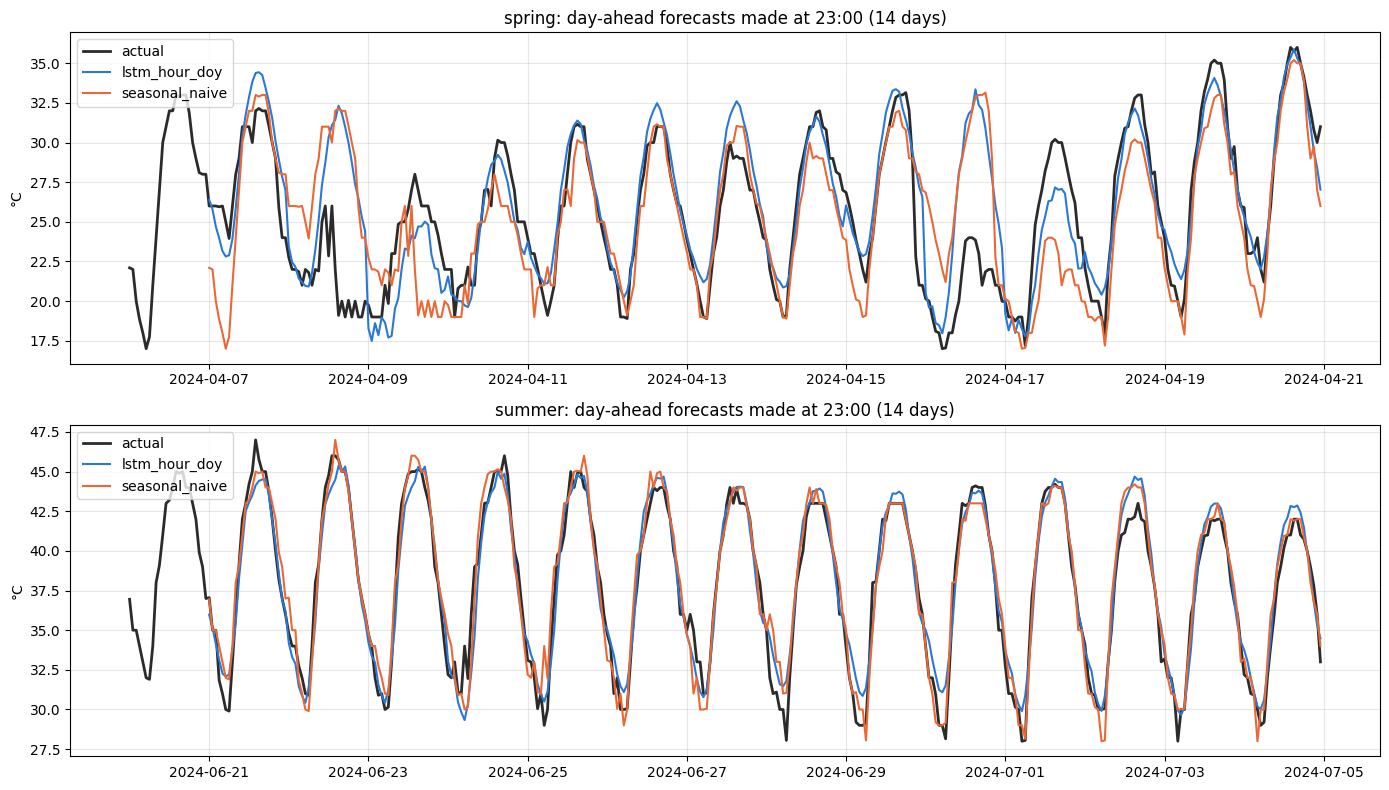

In [23]:
DAILY = on[on.hour == 23]
def best_window(m1, m2, days=14):
    "14-day window inside months m1..m2 with the most complete day-ahead forecasts"
    d = DAILY[(DAILY.month >= m1) & (DAILY.month <= m2)]
    starts = d.normalize().unique()
    counts = [((d >= s) & (d < s + pd.Timedelta(days=days))).sum() for s in starts]
    s = starts[int(np.argmax(counts))]
    return s.strftime("%Y-%m-%d"), (s + pd.Timedelta(days=days)).strftime("%Y-%m-%d")

PERIODS = {"spring": best_window(3, 5), "summer": best_window(6, 8)}
print(PERIODS)
def stitch(pred_df, origins_):
    parts = [pd.Series(pred_df.loc[t].to_numpy(), index=t + pd.to_timedelta(STEPS, unit="h")) for t in origins_]
    return pd.concat(parts) if parts else pd.Series(dtype=float)

fig, axes = plt.subplots(len(PERIODS), 1, figsize=(14, 4 * len(PERIODS)))
for ax, (label, (a, b)) in zip(np.atleast_1d(axes), PERIODS.items()):
    o = DAILY[(DAILY >= pd.Timestamp(a, tz=TZ)) & (DAILY < pd.Timestamp(b, tz=TZ))]
    full = hourly.loc[a:b].index
    ax.plot(full, hourly.loc[a:b].to_numpy(), color=COLORS["actual"], lw=2, label="actual")
    for name, dfp in {D_MODEL: P, "seasonal_naive": SN}.items():
        ax.plot(full, stitch(dfp, o).reindex(full).to_numpy(), lw=1.5, color=color_of(name), label=name)
    ax.set(title=f"{label}: day-ahead forecasts made at 23:00 ({len(o)} days)", ylabel="°C")
    ax.grid(alpha=0.3); ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day3_01_actual_vs_forecast.png", dpi=150, bbox_inches="tight")

📝 **What D1 shows:** In summer (stable weather) the model, seasonal naive and the actual values almost overlap; the model slightly underestimates the highest peaks (e.g. ~45 °C vs 46.5 °C on 21 June). In spring the weather changes more: on 9 April (a cool, flat day) both forecasts missed it, because nothing in the past 72 h announced it. On 16 April a sudden cool day (peak 32 → 23 °C): the model predicted ~26 °C while seasonal naive predicted ~32 °C. The next day seasonal naive repeated the cool day, while the model returned to normal faster. Seasonal naive is always one day late; the LSTM adapts faster, but it still misses sudden changes and smooths extreme peaks.

### D2 — Is the forecast consistently too high or too low? (bias)
Bias = mean of (forecast − actual). Zero = no systematic error. Shown by hours ahead, by hour of day of the target, and by month.

overall bias lstm_hour_doy: +0.09 °C | seasonal_naive: +0.06 °C


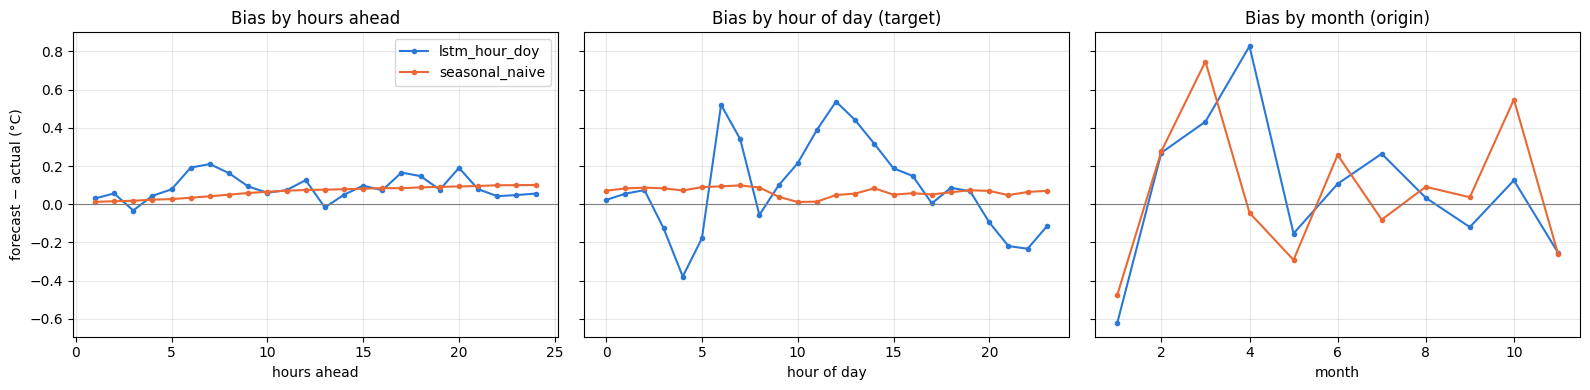

In [24]:
target_hour = ((np.asarray(on.hour)[:, None] + STEPS) % 24).ravel()
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for name, E in {D_MODEL: ERR, "seasonal_naive": ERR_SN}.items():
    c = color_of(name)
    ax[0].plot(STEPS, E.mean(axis=0).to_numpy(), marker="o", ms=3, color=c, label=name)
    ax[1].plot(pd.Series(E.to_numpy().ravel()).groupby(target_hour).mean(), marker="o", ms=3, color=c, label=name)
    ax[2].plot(E.mean(axis=1).groupby(on.month).mean(), marker="o", ms=3, color=c, label=name)
for a_, t_, xl in zip(ax, ["by hours ahead", "by hour of day (target)", "by month (origin)"],
                      ["hours ahead", "hour of day", "month"]):
    a_.axhline(0, color="grey", lw=0.8); a_.set(title=f"Bias {t_}", xlabel=xl); a_.grid(alpha=0.3)
ax[0].set_ylabel("forecast − actual (°C)"); ax[0].legend()
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day3_02_bias.png", dpi=150, bbox_inches="tight")
print(f"overall bias {D_MODEL}: {ERR.to_numpy().mean():+.2f} °C | seasonal_naive: {ERR_SN.to_numpy().mean():+.2f} °C")

📝 **What D2 shows:** Overall bias is almost zero (+0.09 °C for the model, +0.06 °C for seasonal naive), so the model is not systematically too high or too low, and the bias stays small at every horizon (−0.03 to +0.2 °C). By hour of day the model has a small timing pattern: slightly too cold before dawn (~−0.35 °C at 04–05) and slightly too warm in the morning warm-up and midday (~+0.5 °C), while seasonal naive is flat because it copies the same hour from yesterday. By month, March–April have the largest positive bias (+0.4 to +0.8 °C): sudden cool spring days make every forecast too warm. Seasonal naive shows the same monthly pattern, so it comes from the weather, not from the model. All biases stay below 1 °C.

### D3 — Does the model miss the peaks?
For the day-ahead forecasts (made at 23:00) compare the forecast daily **maximum** and **minimum** with the actual ones. A model that smooths the curve predicts maxima too low and minima too high.

,lstm_hour_doy,seasonal_naive
daily max error (°C),0.03,0.07
daily min error (°C),0.60,0.15
daily range forecast / actual,0.94,0.99


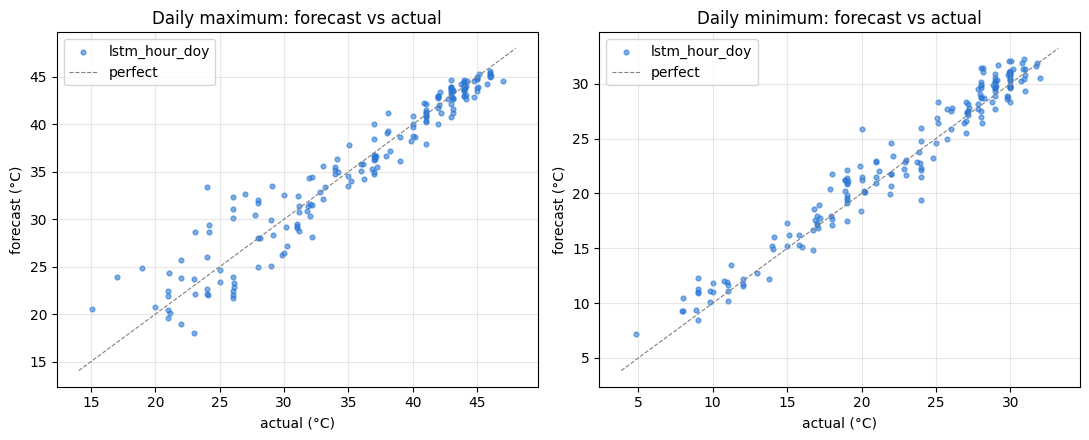

In [25]:
def peaks(pred_df):
    p, a = pred_df.loc[DAILY], A.loc[DAILY]
    return pd.DataFrame({"actual_max": a.max(axis=1), "pred_max": p.max(axis=1),
                         "actual_min": a.min(axis=1), "pred_min": p.min(axis=1)})

PK, PK_SN = peaks(P), peaks(SN)
summary = pd.DataFrame({
    name: {"daily max error (°C)": (k.pred_max - k.actual_max).mean(),
           "daily min error (°C)": (k.pred_min - k.actual_min).mean(),
           "daily range forecast / actual": ((k.pred_max - k.pred_min) / (k.actual_max - k.actual_min)).median()}
    for name, k in {D_MODEL: PK, "seasonal_naive": PK_SN}.items()}).round(2)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, col in zip(ax, ["max", "min"]):
    a_.scatter(PK[f"actual_{col}"], PK[f"pred_{col}"], s=12, alpha=0.6, color=COLORS["lstm"], label=D_MODEL)
    lim = [PK[[f"actual_{col}", f"pred_{col}"]].min().min() - 1, PK[[f"actual_{col}", f"pred_{col}"]].max().max() + 1]
    a_.plot(lim, lim, color="grey", lw=0.8, ls="--", label="perfect")
    a_.set(title=f"Daily {col}imum: forecast vs actual", xlabel="actual (°C)", ylabel="forecast (°C)")
    a_.grid(alpha=0.3); a_.legend()
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day3_03_peaks.png", dpi=150, bbox_inches="tight")

📝 **What D3 shows:** For day-ahead forecasts, the daily maximum is right on average (+0.03 °C), but the daily minimum is forecast 0.6 °C too warm, and the forecast daily range is 6% smaller than the actual one (ratio 0.94). The LSTM produces a smooth curve: it does not go down as deep at night as the real (noisier) temperature. Seasonal naive copies a real day, so its range is right (0.99), but one day late. The scatter shows that summer maxima (40–46 °C) are very close to the perfect line (the very highest peaks slightly under), while in winter/spring (20–30 °C) the errors are much larger because of sudden weather changes.

### D4 — Where are the errors large? (worst forecasts)
The 10 worst forecasts, at most one per day, so a single event is not listed 10 times. `temp_change_°C` = mean of the next 24 h minus mean of the past 72 h: a large value means a **sudden change** (cold front, dust, rain) that the past window could not show.

,origin,lstm_hour_doy_MAE,seasonal_naive_MAE,bias_°C,temp_change_°C
0,2024-04-15 19:00:00+03:00,7.85,6.81,7.85,-5.30
1,2024-04-08 06:00:00+03:00,6.45,6.38,6.45,-6.00
2,2024-04-16 04:00:00+03:00,5.98,5.34,5.98,-5.34
3,2024-04-07 20:00:00+03:00,5.55,6.50,5.55,-4.15
4,2024-02-10 08:00:00+03:00,5.29,3.72,5.29,-1.31
5,2024-04-30 00:00:00+03:00,5.09,3.78,5.08,-5.39
6,2024-02-11 15:00:00+03:00,5.07,3.58,5.07,-3.13
7,2024-04-28 19:00:00+03:00,5.02,5.40,5.02,-3.90
8,2024-02-02 01:00:00+03:00,4.79,5.78,4.79,-6.79
9,2024-10-23 19:00:00+03:00,4.78,4.55,4.78,-3.60


mean |temp change| — worst 10: 4.49 °C | all origins: 1.54 °C


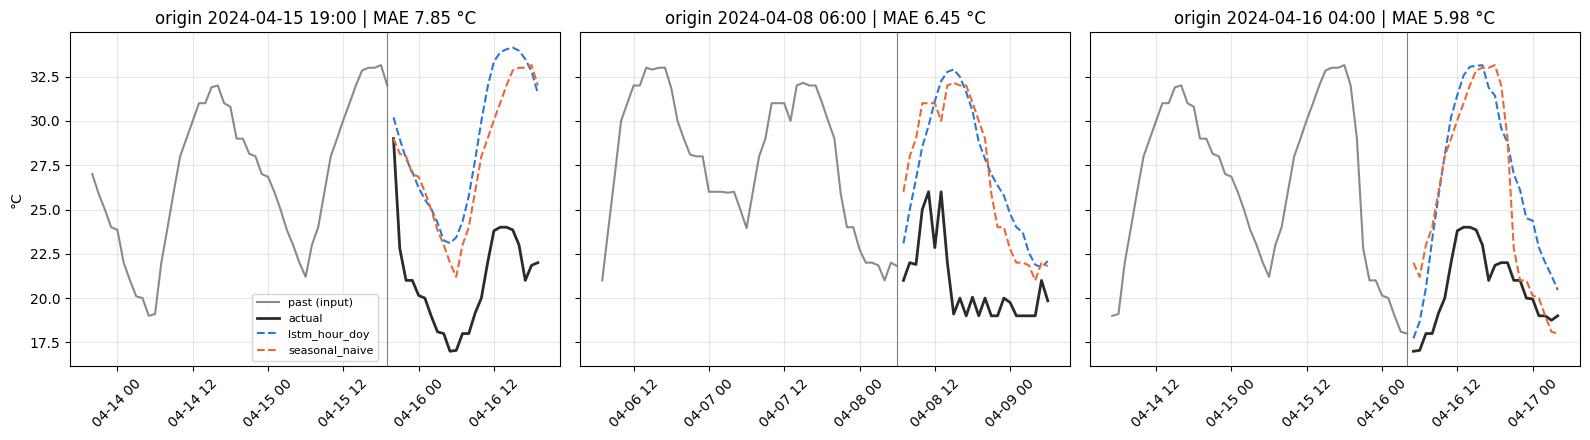

In [26]:
pos = idx.get_indexer(on)
past_mean = np.array([np.mean(y[p - WINDOW + 1: p + 1]) for p in pos])
change = A.mean(axis=1).to_numpy() - past_mean

table = pd.DataFrame({"origin": on, f"{D_MODEL}_MAE": MAE_O.to_numpy(), "seasonal_naive_MAE": MAE_O_SN.to_numpy(),
                      "bias_°C": ERR.mean(axis=1).to_numpy(), "temp_change_°C": change})
table["day"] = table["origin"].dt.date
worst = (table.sort_values(f"{D_MODEL}_MAE", ascending=False).drop_duplicates("day")
              .head(10).drop(columns="day").reset_index(drop=True))
worst = worst.round({c: 2 for c in worst.columns if c != "origin"})
display(worst)
print("mean |temp change| — worst 10:", round(worst["temp_change_°C"].abs().mean(), 2),
      "°C | all origins:", round(np.abs(change).mean(), 2), "°C")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for a_, t in zip(axes, worst["origin"][:3]):
    tt = t + pd.to_timedelta(STEPS, unit="h")
    past = hourly.loc[t - pd.Timedelta(hours=47): t]
    a_.plot(past.index, past.values, color="#8a8a8a", label="past (input)")
    a_.plot(tt, A.loc[t].to_numpy(), color=COLORS["actual"], lw=2, label="actual")
    for name, dfp in {D_MODEL: P, "seasonal_naive": SN}.items():
        a_.plot(tt, dfp.loc[t].to_numpy(), "--", color=color_of(name), label=name)
    a_.axvline(t, color="grey", lw=0.8)
    a_.set_title(f"origin {t:%Y-%m-%d %H:%M} | MAE {MAE_O.loc[t]:.2f} °C"); a_.tick_params(axis="x", rotation=45)
    a_.grid(alpha=0.3)
axes[0].set_ylabel("°C"); axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day3_04_worst_days.png", dpi=150, bbox_inches="tight")

📝 **What D4 shows:** All 10 worst forecasts happen during sudden cooling events (temp_change −1.3 to −6.8 °C): the next 24 h were much colder than the past 72 h. The average absolute temperature change is 4.49 °C for the worst 10 vs 1.54 °C for all origins, so large errors come from weather changes about 3× larger than usual. Bias equals MAE on each of these days: the forecast was too warm at every hour, because nothing in the input window announced the cold. 6 of the 10 are in April and 3 in February (spring and late winter). The 3 worst forecasts all belong to the same cold event of 15–16 April seen in D1. On 7 of these 10 days seasonal naive was slightly better: the LSTM tends to return to the usual seasonal pattern. On extreme days neither model can see the change coming. A next step would be to add inputs that announce a weather change (dew point, pressure, wind).

### D5 — Does it beat the simple baseline over the same horizon?
Share of origins where the LSTM's 24 h MAE is lower than seasonal naive's, overall and by month; and the MAE gap by hours ahead.

lstm_hour_doy beats seasonal naive on 69% of the 4321 origins


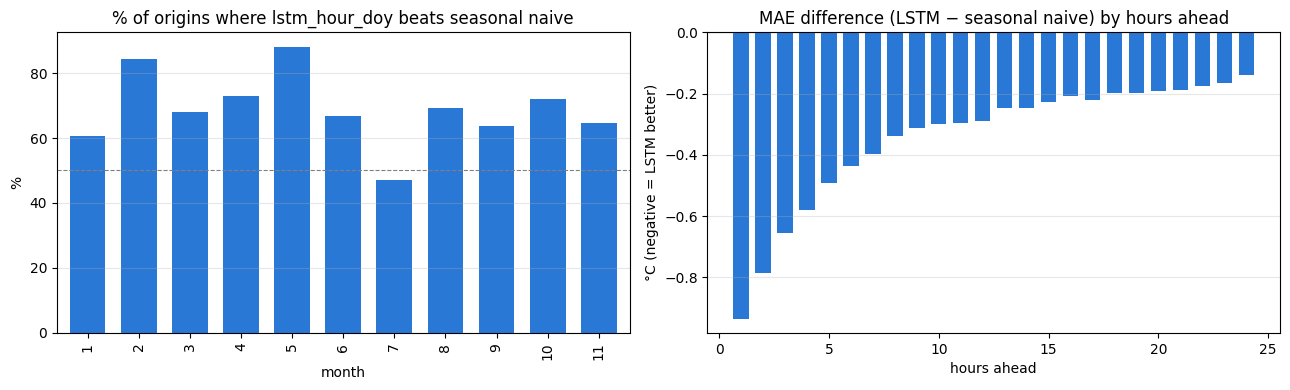

In [27]:
wins = MAE_O < MAE_O_SN
print(f"{D_MODEL} beats seasonal naive on {wins.mean():.0%} of the {len(on)} origins")
gap_h = (ERR.abs().mean(axis=0) - ERR_SN.abs().mean(axis=0))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(100 * wins.groupby(on.month).mean()).plot.bar(ax=ax[0], color=COLORS["lstm"], width=0.7)
ax[0].axhline(50, color="grey", lw=0.8, ls="--")
ax[0].set(title=f"% of origins where {D_MODEL} beats seasonal naive", xlabel="month", ylabel="%")
ax[1].bar(STEPS, gap_h.to_numpy(), color=COLORS["lstm"], width=0.7)
ax[1].axhline(0, color="grey", lw=0.8)
ax[1].set(title="MAE difference (LSTM − seasonal naive) by hours ahead", xlabel="hours ahead", ylabel="°C (negative = LSTM better)")
for a_ in ax: a_.grid(alpha=0.3, axis="y")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day3_05_beat_baseline.png", dpi=150, bbox_inches="tight")

📝 **What D5 shows:** The model beats seasonal naive on 69% of the 4321 validation origins, and in 10 of 11 months (best in May ~86% and February ~84%). Only July is below 50% (~47%): summer weather is so stable that "tomorrow = today" is already very good. The model is better at every horizon (all 24 bars below zero). The gain is largest 1 hour ahead (−0.93 °C): the model knows the latest measurement, while seasonal naive copies a value from 23 h earlier. The gain shrinks to −0.15 °C at 24 hours ahead, where both methods rely on a value 24 h old.

### D6 — 📝 Main conclusions of the error analysis
- **Peaks (D3):** the daily maximum is right on average (+0.03 °C), but the daily minimum is forecast 0.6 °C too warm and the daily range is 6% too small: the LSTM forecasts a smooth curve. The highest summer peaks (>45 °C) are slightly underestimated.
- **Bias (D2):** almost zero overall (+0.09 °C) and at every horizon. Small hour-of-day pattern: a little too cold before dawn (~−0.35 °C) and too warm in the morning warm-up and midday (~+0.5 °C). March–April are too warm (+0.4 to +0.8 °C) because of sudden cool days.
- **Time / season (D1, D2, D4):** errors are largest in spring and late winter, when the weather changes quickly. Summer is the easiest season: forecasts and actual values almost overlap.
- **Baseline (D5):** the model beats seasonal naive on 69% of origins and in 10 of 11 months, and at every horizon (−0.93 °C at 1 h ahead, −0.15 °C at 24 h). Overall validation MAE 1.359 vs 1.701 °C (20% better).
- **Limitation (D4):** all 10 worst forecasts are sudden cooling events (temperature change 4.5 °C on average vs 1.5 °C normally). The past 72 h of temperature cannot announce them, so the model forecasts a normal day (too warm at every hour). On these days seasonal naive is no better. Next step: inputs that announce a weather change (dew point, pressure, wind).

# Midday — Choose the candidate
Bring the results together and choose **one** candidate. Consider the baseline, the validation results, the forecast horizon and the error patterns — not only one score. After this, do **not** reopen model selection unless an integration check shows a real problem.

Training noise ≈ 0.006 °C MAE — a ΔMAE_vs_ref smaller than this is not meaningful


,model,origins,MAE,RMSE,SN_MAE_same_dates,MAE_vs_SN_%,ΔMAE_vs_ref
0,lstm_hour_doy_dow,4321,1.342,1.887,1.701,-21.150,-0.114
1,lstm_hour_doy_u64,4321,1.358,1.926,1.701,-20.156,-0.097
2,lstm_hour_doy,4321,1.359,1.908,1.701,-20.138,-0.097
3,lstm_w168,2208,1.379,1.875,1.604,-13.993,0.006
4,lstm_u64,4321,1.402,1.956,1.701,-17.599,-0.054
5,lstm_hour,4321,1.426,1.978,1.701,-16.168,-0.029
6,lstm_w48,4321,1.430,2.024,1.701,-15.965,-0.026
7,lstm_day2,4321,1.456,2.019,1.701,-14.451,NaN
8,lstm_day2_seed7,4321,1.462,1.994,1.701,-14.072,0.006
9,lstm_drop02,4321,1.488,2.025,1.701,-12.530,0.033


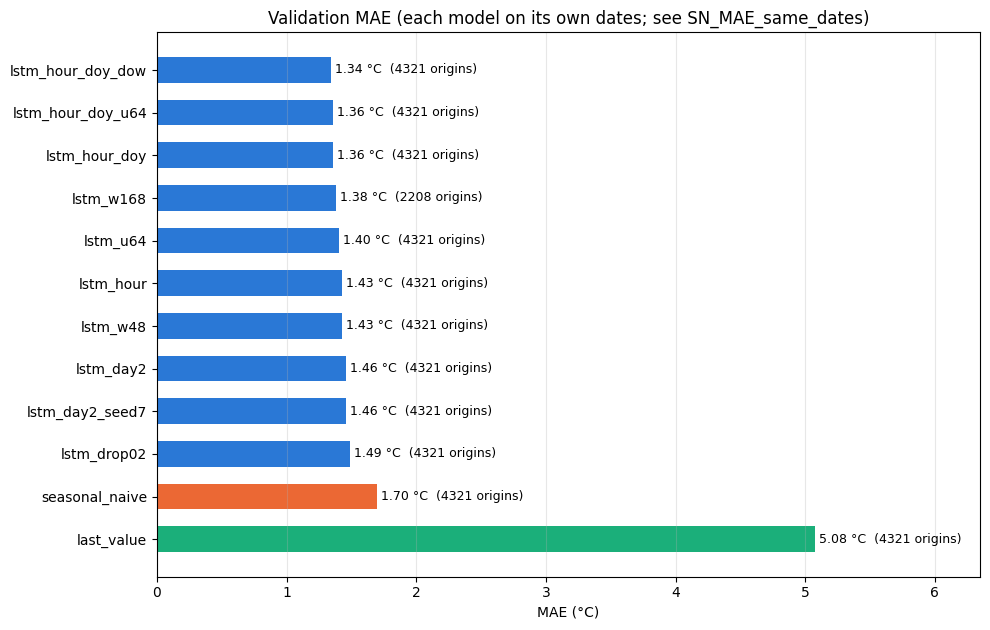

In [28]:
LB = leaderboard()
print(f"Training noise ≈ {NOISE:.3f} °C MAE — a ΔMAE_vs_ref smaller than this is not meaningful")
display(LB)

fig, ax = plt.subplots(figsize=(10, 0.45 * len(LB) + 1))
lb = LB.iloc[::-1]
ax.barh(lb["model"], lb["MAE"], color=[color_of(n) for n in lb["model"]], height=0.6)
for i, (v, n) in enumerate(zip(lb["MAE"], lb["origins"])):
    ax.text(v + 0.03, i, f"{v:.2f} °C  ({n} origins)", va="center", fontsize=9)
ax.set(title="Validation MAE (each model on its own dates; see SN_MAE_same_dates)", xlabel="MAE (°C)")
ax.grid(alpha=0.3, axis="x"); ax.set_xlim(0, LB["MAE"].max() * 1.25)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day3_06_leaderboard.png", dpi=150, bbox_inches="tight")

# Decision 

- **Selected candidate:** `lstm_hour_doy` — LSTM (32 units), 72 h input window, inputs: temperature + hour of day + day of year (sin/cos), direct 24 h output.
- **Why:** validation MAE 1.359 °C and RMSE 1.908 °C on the same 4321 dates, vs 1.701 / 2.418 °C for seasonal naive (−20%) and 1.456 / 2.019 °C for the Day 2 LSTM (−0.097 °C, about 16× the training noise). It beats seasonal naive on 69% of origins, in 10 of 11 months and at every horizon (D5). Bias is almost zero (D2). Both added inputs are calendar values, known at forecast time (no leakage).
- **Not selected although slightly lower MAE:** `lstm_hour_doy_dow` (1.342, −0.017) — below our safety margin (0.02), and temperature has no weekly cycle, so the gain is likely training randomness. `lstm_hour_doy_u64` (1.358) — same MAE, worse RMSE, twice the size. Simpler model preferred.
- **Rejected changes and why:** 168 h window — no gain on the same 2208 dates and loses half of the evaluation dates; dropout 0.2 — worse (+0.033), the model was underfitting; 48 h window — small mixed gain (RMSE not better).
- **Known limitation:** sudden cooling events (spring, late winter) are missed because the past 72 h cannot announce them (D4).

In [29]:
SELECTED = "lstm_hour_doy"      # chosen model (see decioion above)
assert SELECTED in MODELS, f"{SELECTED} was not trained in this notebook"
print("Selected:", SELECTED, CONFIGS[SELECTED])

Selected: lstm_hour_doy {'window': 72, 'horizon': 24, 'features': ['temp', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos'], 'units': 32, 'dropout': 0.0, 'lr': 0.001, 'batch_size': 64, 'max_epochs': 20, 'patience': 3, 'seed': 42, 'train_windows': 18246, 'epochs_run': 19, 'best_epoch': 16}


# Part 3 — Afternoon checkpoint
## Track A — Combine sequence preparation and forecast
1. Confirm the selected forecast uses the agreed dates and input window
2. Rerun validation and compare with the simple baseline on exactly the same dates
3. Check that predictions are converted back to °C
4. Save the model and scaler, and document the input window and feature order
5. Reload from disk and check the saved pipeline gives the same forecast

📁 **Keep an untouched copy** of the working notebook and saved files: do not edit `02_forecast_baseline_team_completed_V1.ipynb`; every experiment model stays in `../models/experiments/`.

### A1 — Confirm dates and input window

In [30]:
cfg = CONFIGS[SELECTED]
sel_origins = PREDS[SELECTED].index
assert cfg["horizon"] == HORIZON == 24
assert sel_origins.isin(EVAL_ORIGINS).all()
print(json.dumps(cfg, indent=2))
print(f"evaluation dates: {sel_origins[0]} → {sel_origins[-1]} | {len(sel_origins)} of {len(EVAL_ORIGINS)} origins")

{
  "window": 72,
  "horizon": 24,
  "features": [
    "temp",
    "hour_sin",
    "hour_cos",
    "doy_sin",
    "doy_cos"
  ],
  "units": 32,
  "dropout": 0.0,
  "lr": 0.001,
  "batch_size": 64,
  "max_epochs": 20,
  "patience": 3,
  "seed": 42,
  "train_windows": 18246,
  "epochs_run": 19,
  "best_epoch": 16
}
evaluation dates: 2024-01-04 02:00:00+03:00 → 2024-11-25 23:00:00+03:00 | 4321 of 4321 origins


### A2 — Rerun validation and compare with the baselines on exactly the same dates

In [31]:
model = MODELS[SELECTED]
X_sel, _ = make_xy(sel_origins, cfg["window"], cfg["features"])
pred_sel = to_celsius(model.predict(X_sel, verbose=0))
assert np.allclose(pred_sel, PREDS[SELECTED].to_numpy(), atol=1e-3), "rerun differs from the stored predictions"

FINAL = pd.DataFrame([{"approach": n, **score(n, on=sel_origins)} for n in ["last_value", "seasonal_naive", SELECTED]])
FINAL["MAE_vs_SN_%"] = 100 * (FINAL["MAE"] / FINAL.loc[1, "MAE"] - 1)
FINAL.round(3)

,approach,MAE,RMSE,origins,MAE_vs_SN_%
0,last_value,5.078,6.332,4321,198.435
1,seasonal_naive,1.701,2.418,4321,0.000
2,lstm_hour_doy,1.359,1.908,4321,-20.138


### A3 — Predictions are in °C

In [32]:
a_sel = ACTUAL.loc[sel_origins].to_numpy()
print(f"forecast °C: min {pred_sel.min():.1f} | max {pred_sel.max():.1f} | mean {pred_sel.mean():.2f}")
print(f"actual   °C: min {a_sel.min():.1f} | max {a_sel.max():.1f} | mean {a_sel.mean():.2f}")
assert -5 < pred_sel.min() and pred_sel.max() < 60, "values do not look like °C — check to_celsius"
assert abs(pred_sel.mean() - a_sel.mean()) < 1.5
print("✔ predictions are in °C")

forecast °C: min 5.7 | max 46.9 | mean 29.65
actual   °C: min 4.8 | max 47.0 | mean 29.57
✔ predictions are in °C


### A4 — Save the model pipeline
- `../models/madar_lstm.keras` — the trained model
- `../models/scaler.json` — train-only scaler (how to reverse it: `°C = z × std + mean`)
- `../models/pipeline_config.json` — window, horizon, **feature order**, feature definitions, data cleaning rules, validation scores

In [33]:
FEATURE_DEFINITIONS = {
    "temp":     "(air_temperature_C - mean_C) / std_C",
    "hour_sin": "sin(2π · hour / 24)",       "hour_cos": "cos(2π · hour / 24)",
    "doy_sin":  "sin(2π · day_of_year / 365.25)", "doy_cos": "cos(2π · day_of_year / 365.25)",
    "dow_sin":  "sin(2π · day_of_week / 7)",  "dow_cos":  "cos(2π · day_of_week / 7)",
}
SCALER = {"type": "standard", "applies_to": "temp", "mean_C": MU, "std_C": SIGMA,
          "fit_on": "train", "fit_range": list(SPLITS["train"]), "n_values": int(len(train_vals))}
PIPELINE = {
    "model_file": "madar_lstm.keras", "selected_experiment": SELECTED,
    "station": STATION, "timezone": TZ, "target": "air_temperature", "unit": "°C",
    "cleaning": {"fake_value_threshold": FAKE_THRESHOLD, "readings": "minute 0 only, repeats averaged", "gaps": "not filled"},
    "window_hours": cfg["window"], "horizon_hours": HORIZON,
    "features": cfg["features"],                                   # order matters!
    "feature_definitions": {f: FEATURE_DEFINITIONS[f] for f in cfg["features"]},
    "scaler": SCALER, "splits": SPLITS,
    "validation": {n: {k: round(v, 3) for k, v in score(n, on=sel_origins).items()}
                   for n in ["seasonal_naive", SELECTED]},
    "settings": cfg, "created": datetime.datetime.now().isoformat(timespec="seconds"),
}
model.save(f"{MODEL_DIR}/madar_lstm.keras")
with open(f"{MODEL_DIR}/scaler.json", "w") as f:
    json.dump(SCALER, f, indent=2)
with open(f"{MODEL_DIR}/pipeline_config.json", "w") as f:
    json.dump(PIPELINE, f, indent=2, ensure_ascii=False)
print(json.dumps({k: PIPELINE[k] for k in ["selected_experiment", "window_hours", "horizon_hours", "features"]}, indent=2))

{
  "selected_experiment": "lstm_hour_doy",
  "window_hours": 72,
  "horizon_hours": 24,
  "features": [
    "temp",
    "hour_sin",
    "hour_cos",
    "doy_sin",
    "doy_cos"
  ]
}


### A5 — Reload from disk and check
The same loading and forecasting functions are used in the demo notebook. If this check passes, the demo will give the same numbers as the validation.

In [34]:
def load_pipeline(model_dir=MODEL_DIR):
    with open(f"{model_dir}/pipeline_config.json") as f:
        config = json.load(f)
    return keras.models.load_model(f"{model_dir}/{config['model_file']}"), config

def build_features(index, temp_c, config):
    sc = config["scaler"]
    hour, doy, dow = index.hour.to_numpy(), index.dayofyear.to_numpy(), index.dayofweek.to_numpy()
    cols = {"temp": (np.asarray(temp_c, dtype=float) - sc["mean_C"]) / sc["std_C"],
            "hour_sin": np.sin(2 * np.pi * hour / 24),    "hour_cos": np.cos(2 * np.pi * hour / 24),
            "doy_sin":  np.sin(2 * np.pi * doy / 365.25), "doy_cos":  np.cos(2 * np.pi * doy / 365.25),
            "dow_sin":  np.sin(2 * np.pi * dow / 7),      "dow_cos":  np.cos(2 * np.pi * dow / 7)}
    return np.stack([cols[f] for f in config["features"]], axis=-1)

def forecast(series, origin, model, config):
    W, H, tz = config["window_hours"], config["horizon_hours"], config["timezone"]
    origin = pd.Timestamp(origin)
    origin = origin.tz_localize(tz) if origin.tzinfo is None else origin.tz_convert(tz)
    past = series.loc[origin - pd.Timedelta(hours=W - 1): origin]
    if len(past) != W or past.isna().any():
        raise ValueError(f"need {W} complete hours ending at {origin}")
    z = model.predict(build_features(past.index, past.to_numpy(), config)[None], verbose=0)[0]
    sc = config["scaler"]
    return pd.Series(z * sc["std_C"] + sc["mean_C"],
                     index=origin + pd.to_timedelta(np.arange(1, H + 1), unit="h"), name="forecast_C")

model_disk, config_disk = load_pipeline()
for t in sel_origins[[0, len(sel_origins) // 2, -1]]:
    fc = forecast(hourly, t, model_disk, config_disk)
    assert np.allclose(fc.to_numpy(), PREDS[SELECTED].loc[t].to_numpy(), atol=1e-3)
print("✔ the saved pipeline reproduces the validation forecasts")

✔ the saved pipeline reproduces the validation forecasts


### A6 — Save all predictions and the experiment log

In [35]:
long = pd.concat({n: d.stack() for n, d in PREDS.items()}, axis=1)
long.index.names = ["origin", "horizon"]
long.insert(0, "actual", ACTUAL.stack().reindex(long.index))
long = long.reset_index()
long.insert(1, "target_time", long["origin"] + pd.to_timedelta(long["horizon"], unit="h"))
long.to_csv(f"{PRED_DIR}/validation_day3_all_models.csv", index=False)
LB.to_csv(f"{PRED_DIR}/validation_day3_leaderboard.csv", index=False)
print("saved:", f"{PRED_DIR}/validation_day3_all_models.csv", long.shape, "|", LOG_FILE)
print("figures:", sorted(f for f in os.listdir(FIG_DIR) if f.startswith("day3_")))

saved: ../reports/predictions/validation_day3_all_models.csv (103704, 16) | ../reports/experiment_log_day3.csv
figures: ['day3_01_actual_vs_forecast.png', 'day3_02_bias.png', 'day3_03_peaks.png', 'day3_04_worst_days.png', 'day3_05_beat_baseline.png', 'day3_06_leaderboard.png']


### A7 — Final test (2025, run once)
The selected model, settings and dates were fixed **before** this cell, using validation only. This is the one evaluation on the untouched test period (2025): same horizon, same metrics in °C, compared with the simple forecasts **on the same dates**. Nothing is tuned after it.

test period: 2025-01-04 02:00 → 2025-08-23 04:00 | 2992 origins
lstm_hour_doy: validation MAE 1.359 °C → test MAE 1.372 °C
beats seasonal naive on 64% of test origins


,approach,MAE,RMSE,origins,MAE_vs_SN_%
0,lstm_hour_doy,1.372,1.891,2992,-20.979
1,seasonal_naive,1.736,2.385,2992,0.000
2,last_value,5.053,6.340,2992,191.082


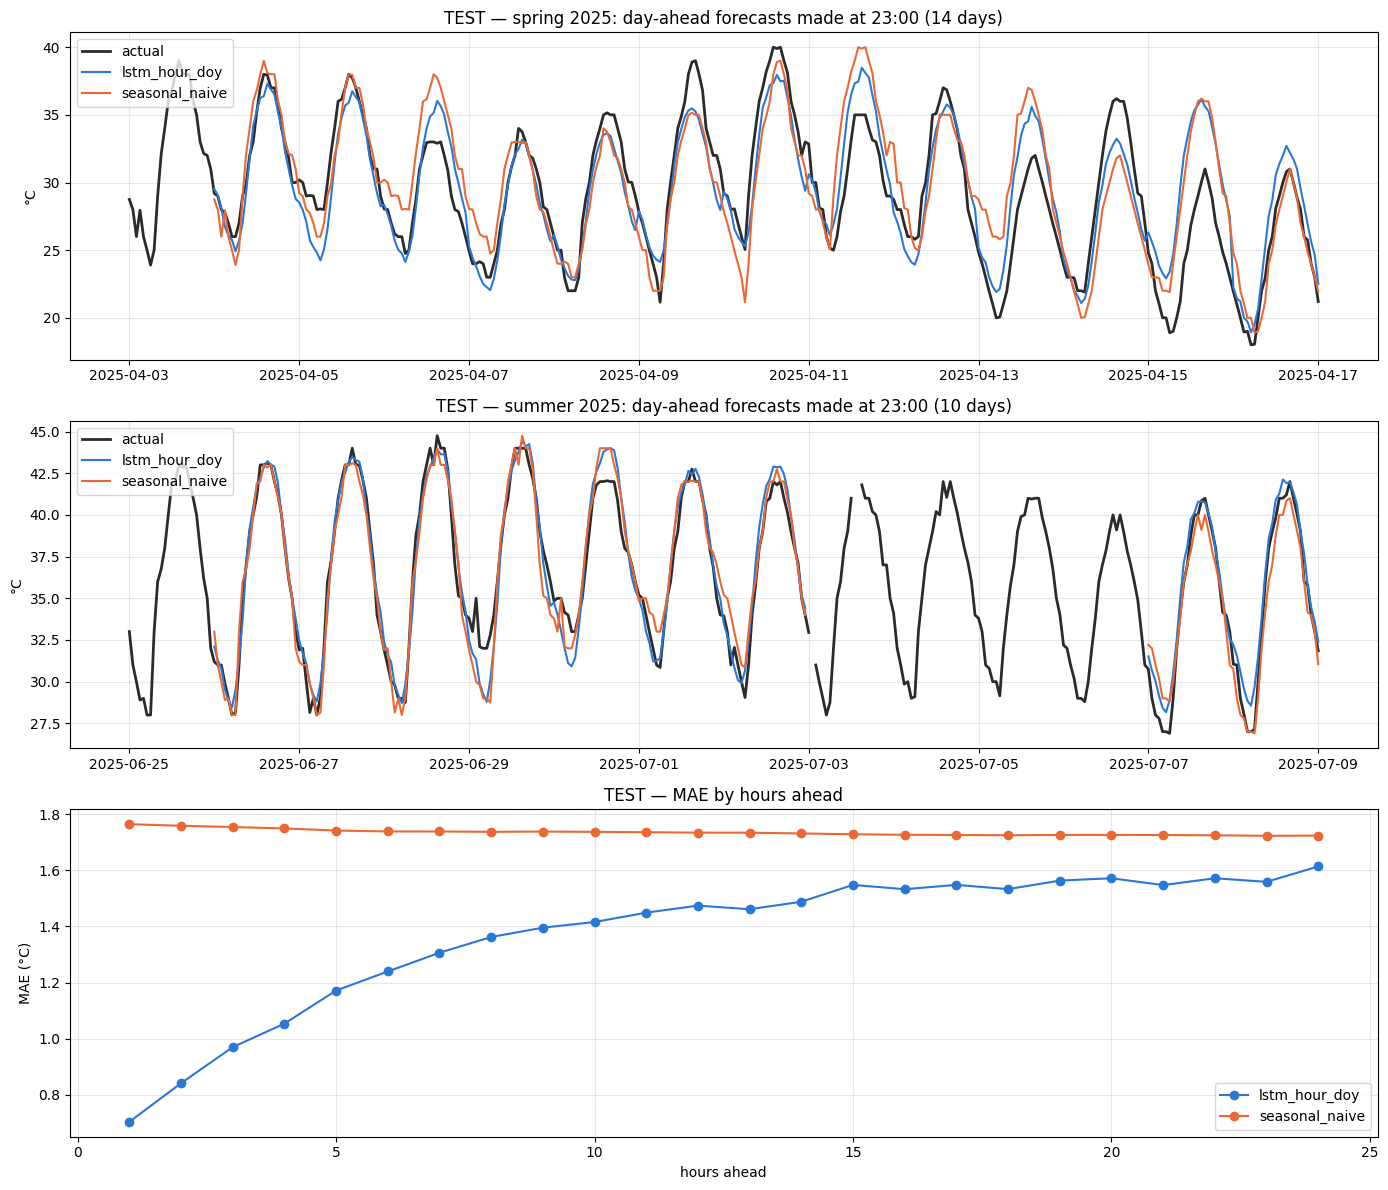

In [36]:
o_test = ORIGINS["test"]
pos_t  = idx.get_indexer(o_test)
A_test = y[pos_t[:, None] + STEPS]                                    # actual °C, (n, 24)
X_test, _ = make_xy(o_test, cfg["window"], cfg["features"])         # past values only
P_test = {SELECTED:         to_celsius(model.predict(X_test, verbose=0)),
          "seasonal_naive": y[pos_t[:, None] + STEPS - 24],
          "last_value":     np.repeat(y[pos_t][:, None], HORIZON, axis=1)}
assert not np.isnan(A_test).any() and all(not np.isnan(p).any() for p in P_test.values())

TEST = pd.DataFrame([{"approach": n, "MAE": mae(A_test, p), "RMSE": rmse(A_test, p), "origins": len(o_test)}
                     for n, p in P_test.items()])
TEST["MAE_vs_SN_%"] = 100 * (TEST["MAE"] / TEST.loc[TEST.approach == "seasonal_naive", "MAE"].item() - 1)
TEST.to_csv(f"{PRED_DIR}/test_final_scores.csv", index=False)

err_l = np.abs(P_test[SELECTED] - A_test)
err_s = np.abs(P_test["seasonal_naive"] - A_test)
wins_t = (err_l.mean(axis=1) < err_s.mean(axis=1)).mean()
print(f"test period: {o_test[0]:%Y-%m-%d %H:%M} → {o_test[-1]:%Y-%m-%d %H:%M} | {len(o_test)} origins")
print(f"{SELECTED}: validation MAE {score(SELECTED)['MAE']:.3f} °C → test MAE {mae(A_test, P_test[SELECTED]):.3f} °C")
print(f"beats seasonal naive on {wins_t:.0%} of test origins")
display(TEST.round(3))

# Plot: actual vs predicted on the test period (day-ahead forecasts made at 23:00) + MAE by hours ahead
P_df  = pd.DataFrame(P_test[SELECTED], index=o_test, columns=STEPS)
SN_df = pd.DataFrame(P_test["seasonal_naive"], index=o_test, columns=STEPS)
D_T = o_test[o_test.hour == 23]

def best_window_t(m1, m2, days=14):
    d = D_T[(D_T.month >= m1) & (D_T.month <= m2)]
    starts = d.normalize().unique()
    counts = [((d >= s) & (d < s + pd.Timedelta(days=days))).sum() for s in starts]
    s = starts[int(np.argmax(counts))]
    return s, s + pd.Timedelta(days=days)

def stitch_t(df, origins_):
    parts = [pd.Series(df.loc[t].to_numpy(), index=t + pd.to_timedelta(STEPS, unit="h")) for t in origins_]
    return pd.concat(parts) if parts else pd.Series(dtype=float)

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
for ax, (label, (m1, m2)) in zip(axes[:2], {"spring 2025": (3, 5), "summer 2025": (6, 8)}.items()):
    a, b = best_window_t(m1, m2)
    o = D_T[(D_T >= a) & (D_T < b)]
    full = pd.date_range(a, b, freq="h", tz=TZ)
    ax.plot(full, hourly.reindex(full).to_numpy(), color=COLORS["actual"], lw=2, label="actual")
    for name, dfp in {SELECTED: P_df, "seasonal_naive": SN_df}.items():
        ax.plot(full, stitch_t(dfp, o).reindex(full).to_numpy(), lw=1.5, color=color_of(name), label=name)
    ax.set(title=f"TEST — {label}: day-ahead forecasts made at 23:00 ({len(o)} days)", ylabel="°C")
    ax.grid(alpha=0.3); ax.legend(loc="upper left")
axes[2].plot(STEPS, err_l.mean(axis=0), marker="o", color=color_of(SELECTED), label=SELECTED)
axes[2].plot(STEPS, err_s.mean(axis=0), marker="o", color=COLORS["seasonal_naive"], label="seasonal_naive")
axes[2].set(title="TEST — MAE by hours ahead", xlabel="hours ahead", ylabel="MAE (°C)")
axes[2].grid(alpha=0.3); axes[2].legend()
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/day4_test_actual_vs_forecast.png", dpi=150, bbox_inches="tight")

📝 **Final test result:** On the untouched 2025 period (2,992 origins), `lstm_hour_doy` scored MAE 1.372 °C and RMSE 1.891 °C, vs seasonal naive MAE 1.736 °C and RMSE 2.385 °C (−21.0% MAE). Validation MAE was 1.359 °C, so the test result is almost the same: the model generalises to new data and was not overfitted to the validation period. It beats seasonal naive on 64% of test origins and at every horizon (MAE 0.71 °C at 1 h ahead, about 1.6 °C at 24 h). Like on validation, the largest errors come from sudden weather changes in spring. The empty parts of the summer plot are gaps in the data. The test was run once, in a full top-to-bottom run, and nothing was changed after it.

## Track B — Presentation outline 
Decide the order, make placeholder slides today, fill them tomorrow. Choose one look and feel (e.g. desert/sun colors, one font, the same 4 colors for actual / LSTM / seasonal naive / last value as in the plots).

| # | Slide | Content | Visual |
|---|---|---|---|
| 1 | Title | Madar — forecasting Riyadh's temperature 24 h ahead | photo / logo |
| 2 | The problem | Why a 24 h forecast is useful; who would use it | — |
| 3 | The data | KING KHALED INTL, hourly 2021–2025, fake values, gaps | Day 1/2 data plot |
| 4 | How we test fairly | Time split, 72 h in → 24 h out, no future values, same dates for all | simple timeline diagram |
| 5 | Simple forecasts | Last value vs same hour yesterday — why seasonal naive is strong | `05_baselines_examples.png` |
| 6 | The LSTM | 72 hours in, 24 hours out, small model | simple diagram |
| 7 | Results | MAE / RMSE on 4,321 validation dates | `day3_06_leaderboard.png` |
| 8 | Where it wins | By hours ahead and by month | `08_all_models_error.png`, `day3_05_beat_baseline.png` |
| 9 | What we tried today | Experiments: what, why, result (from the log) | small table |
| 10 | Errors and limits | Peaks, bias, sudden changes | `day3_03_peaks.png`, `day3_04_worst_days.png` |
| 11 | Live demo | Forecast for the next 24 h | `04_prediction_demo.ipynb` |
| 12 | Conclusion & next steps | Test-set check, future calendar inputs, more stations | — |

Placeholders still open: final test-set score (only at the final evaluation). Selected model: `lstm_hour_doy`. D6 conclusions: done.


# Required deliverable (end of Day 3)
- [ ] **Presentation framework:** all main slides, main visuals, main results/conclusions (or placeholders) — rough is fine
- [ ] **Complete pipeline:** this notebook runs top to bottom (*Kernel → Restart & Run All*), uses headings, and ends with a saved model pipeline in `../models/`
- [ ] **Clean demo notebook** (`04_prediction_demo.ipynb`): loads the pipeline from disk, runs a forecast on new data in **one cell**, shows it as a chart
- [ ] Experiment log saved: `../reports/experiment_log_day3.csv` (what / why / result for every experiment)
- [ ] Error-analysis plots and the main conclusion saved (Track D)
- [ ] Test period still untouched

## Pitfalls
- **Do not change the evaluation dates** or the horizon — a longer window is compared on the same reduced dates for all models.
- **Do not use future information** — features, scaler and windows use only values known at forecast time.
- **Do not chase a tiny score improvement** — compare with the training noise and look at the plots and error patterns.
- **Do not start the slides tomorrow** — build the outline today and save the plots.

